# Passo 2 — Treino do YOLO com o dataset da FootAR

**Objetivo:** obter um modelo que distinga `player`, `goalkeeper`, `referee` e `ball` em transmissões da Liga Portugal, ultrapassando as limitações do modelo genérico identificadas no Passo 1.

**Dataset:** `football-players-and-ball` (Roboflow da FootAR), anotado com frames destes mesmos vídeos.

**Método:** *transfer learning*. Parte-se do YOLOv8m pré-treinado no COCO e afina-se com o dataset da FootAR.

## 2.1 Configuração e verificação da GPU
O treino é muito mais rápido com uma GPU NVIDIA. Esta célula confirma se o PyTorch a consegue usar.

In [1]:
from pathlib import Path
import torch

BASE = Path(r"C:\Users\simao\OneDrive\Documentos\TDIA\3 ano\1_Semestre\PAIA-Projeto Aplicado de Inteligência Artificial I\OneDrive_2026-09-25\FOOTAR_DETECAO_DE_EVENTOS")
PASTA_DATASET = BASE / "dataset"
PASTA_TREINOS = BASE / "treinos"

print("GPU disponível:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

GPU disponível: False


## 2.2 Descarregar o dataset do Roboflow

**Dataset utilizado (provisório):** *football-players-detection* (Roboflow Universe), copiado (fork) para o workspace do grupo.
Enquanto não há acesso ao workspace privado da FootAR, é usado este dataset público, que tem as mesmas classes e imagens do mesmo tipo (transmissões televisivas de futebol).

| | |
|---|---|
| **Classes** | `ball`, `goalkeeper`, `player`, `referee` |
| **Total de imagens** | 372 |
| **Treino / Validação / Teste** | 298 / 49 / 25 |
| **Formato** | YOLOv8 (uma imagem `.jpg` + um ficheiro `.txt` com as caixas, por imagem) |
| **Pré-processamento no Roboflow** | nenhum (o redimensionamento é feito pelo YOLO no treino) |

Esta célula:
1. instala as bibliotecas `ultralytics` (YOLO) e `roboflow`;
2. descarrega a versão 1 do dataset em formato YOLOv8;
3. mostra o ficheiro `data.yaml`, que indica onde estão as imagens e quais são as classes.

**Nota:** quando a FootAR der acesso ao dataset `football-players-and-ball`, com imagens da Liga Portugal, basta alterar o workspace e o projeto nesta célula e voltar a treinar.

In [2]:
!pip install -q ultralytics roboflow

from roboflow import Roboflow
rf = Roboflow(api_key="0rSNhH0082ZuEdclxFLg")
project = rf.workspace("simos-workspace-6b8qg").project("football-players-detection-3zvbc-untrg")
version = project.version(1)
dataset = version.download("yolov8")

print(dataset.location)
!cat {dataset.location}/data.yaml

  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.

[notice] A new release of pip is available: 26.1.1 -> 26.2.1
[notice] To update, run: C:\Program Files\Python311\python.exe -m pip install --upgrade pip


loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to football-players-detection-1 in yolov8:: 100%|██████████| 748/748 [00:01<00:00, 732.36it/s]


c:\Users\simao\OneDrive\Documentos\TDIA\3 ano\1_Semestre\PAIA-Projeto Aplicado de Inteligência Artificial I\OneDrive_2026-09-25\FOOTAR_DETECAO_DE_EVENTOS\note book\football-players-detection-1


'cat' is not recognized as an internal or external command,
operable program or batch file.


In [3]:
print(open(f"{dataset.location}/data.yaml", encoding="utf-8").read())

names:
- ball
- goalkeeper
- player
- referee
nc: 4
roboflow:
  license: CC BY 4.0
  project: football-players-detection-3zvbc-untrg
  url: https://app.roboflow.com/simos-workspace-6b8qg/football-players-detection-3zvbc-untrg/1
  version: 1
  workspace: simos-workspace-6b8qg
test: ../test/images
train: ../train/images
val: ../valid/images



### Estrutura do dataset (`data.yaml`)

| Campo | Valor | Significado |
|---|---|---|
| `nc` | 4 | número de classes |
| `names` | `ball` (0), `goalkeeper` (1), `player` (2), `referee` (3) | nome de cada classe; o número é o ID usado nas anotações |
| `train` / `val` / `test` | pastas de imagens | conjuntos de treino, validação e teste |
| `license` | CC BY 4.0 | dataset público, pode ser usado citando a fonte |

Cada imagem `.jpg` tem um ficheiro `.txt` com o mesmo nome na pasta `labels`. Cada linha é um objeto anotado:
`classe  x_centro  y_centro  largura  altura` (valores normalizados entre 0 e 1).

## 2.3 Análise exploratória do dataset
Antes de treinar, verifica-se quantos objetos existem de cada classe e visualizam-se algumas anotações.
Um desequilíbrio forte (por exemplo, poucos árbitros ou poucas bolas) ajuda a explicar mais tarde o desempenho do modelo.

In [9]:
from pathlib import Path
from collections import Counter

BASE = Path(r"C:\Users\simao\OneDrive\Documentos\TDIA\3 ano\1_Semestre\PAIA-Projeto Aplicado de Inteligência Artificial I\OneDrive_2026-09-25\FOOTAR_DETECAO_DE_EVENTOS")
DS = list(BASE.rglob("data.yaml"))[0].parent          # encontra a pasta do dataset
NOMES = ["ball", "goalkeeper", "player", "referee"]

print("Dataset:", DS.name, "\n")
for split in ["train", "valid", "test"]:
    cont = Counter()
    labels = list((DS / split / "labels").glob("*.txt"))
    for f in labels:
        for linha in f.read_text().splitlines():
            if linha.strip():
                cont[NOMES[int(linha.split()[0])]] += 1
    print(f"{split:>5}: {len(labels)} imagens | " +
          ", ".join(f"{n}={cont[n]}" for n in NOMES))

Dataset: football-players-detection-1 

train: 298 imagens | ball=258, goalkeeper=230, player=5955, referee=690
valid: 49 imagens | ball=45, goalkeeper=39, player=973, referee=117
 test: 25 imagens | ball=24, goalkeeper=19, player=500, referee=56


### Distribuição das classes

| Classe | Treino | Validação | Teste | Total | % |
|---|---|---|---|---|---|
| `player` | 5 955 | 973 | 500 | 7 428 | 83,4% |
| `referee` | 690 | 117 | 56 | 863 | 9,7% |
| `ball` | 258 | 45 | 24 | 327 | 3,7% |
| `goalkeeper` | 230 | 39 | 19 | 288 | 3,2% |
| **Total** | | | | **8 906** | |

**Conclusões:**
- O dataset é fortemente **desequilibrado**: `player` representa 83% dos objetos.
- `referee` tem ~2,3 instâncias por imagem, porque inclui o árbitro principal e os árbitros assistentes.
- `ball` aparece em menos de uma instância por imagem (a bola nem sempre está visível) e é o objeto mais pequeno. É a classe onde se espera **pior desempenho**, tal como no grupo anterior (mAP50 de 68,1% na bola).
- `goalkeeper` tem poucos exemplos (~1 por imagem), o que pode levar a confusões com `player`.

Estas observações servem de referência para interpretar as métricas por classe após o treino.

### Visualização de anotações
Quatro imagens aleatórias do conjunto de treino com as caixas anotadas.
Cores: **branco** = bola · **amarelo** = guarda-redes · **azul** = jogador · **vermelho** = árbitro.

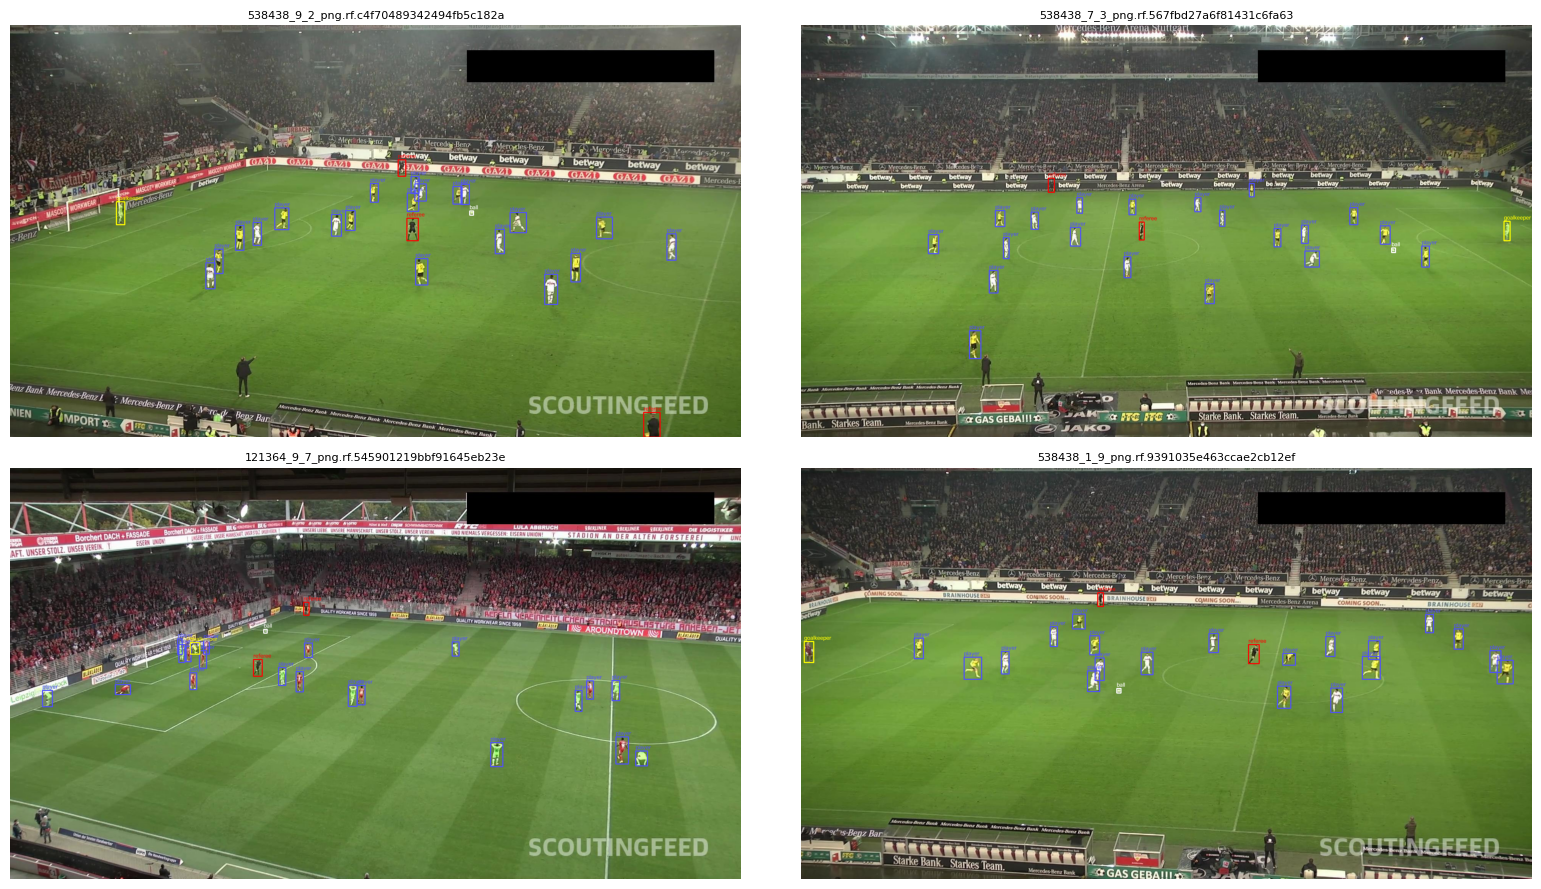

In [10]:
import cv2, numpy as np, random
import matplotlib.pyplot as plt

CORES = {0: (255, 255, 255), 1: (0, 255, 255), 2: (255, 80, 80), 3: (0, 0, 255)}  # BGR

imgs = random.sample(list((DS / "train" / "images").glob("*.jpg")), 4)
fig, axs = plt.subplots(2, 2, figsize=(16, 9))

for ax, img_path in zip(axs.flat, imgs):
    img = cv2.imdecode(np.fromfile(str(img_path), dtype=np.uint8), cv2.IMREAD_COLOR)
    h, w = img.shape[:2]
    lbl = DS / "train" / "labels" / (img_path.stem + ".txt")
    for linha in lbl.read_text().splitlines():
        if not linha.strip():
            continue
        c, xc, yc, bw, bh = map(float, linha.split()[:5])
        x1, y1 = int((xc - bw/2) * w), int((yc - bh/2) * h)
        x2, y2 = int((xc + bw/2) * w), int((yc + bh/2) * h)
        cv2.rectangle(img, (x1, y1), (x2, y2), CORES[int(c)], 2)
        cv2.putText(img, NOMES[int(c)], (x1, y1 - 4), cv2.FONT_HERSHEY_SIMPLEX, 0.5, CORES[int(c)], 1)
    ax.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    ax.set_title(img_path.name[:40], fontsize=8)
    ax.axis("off")

plt.tight_layout(); plt.show()

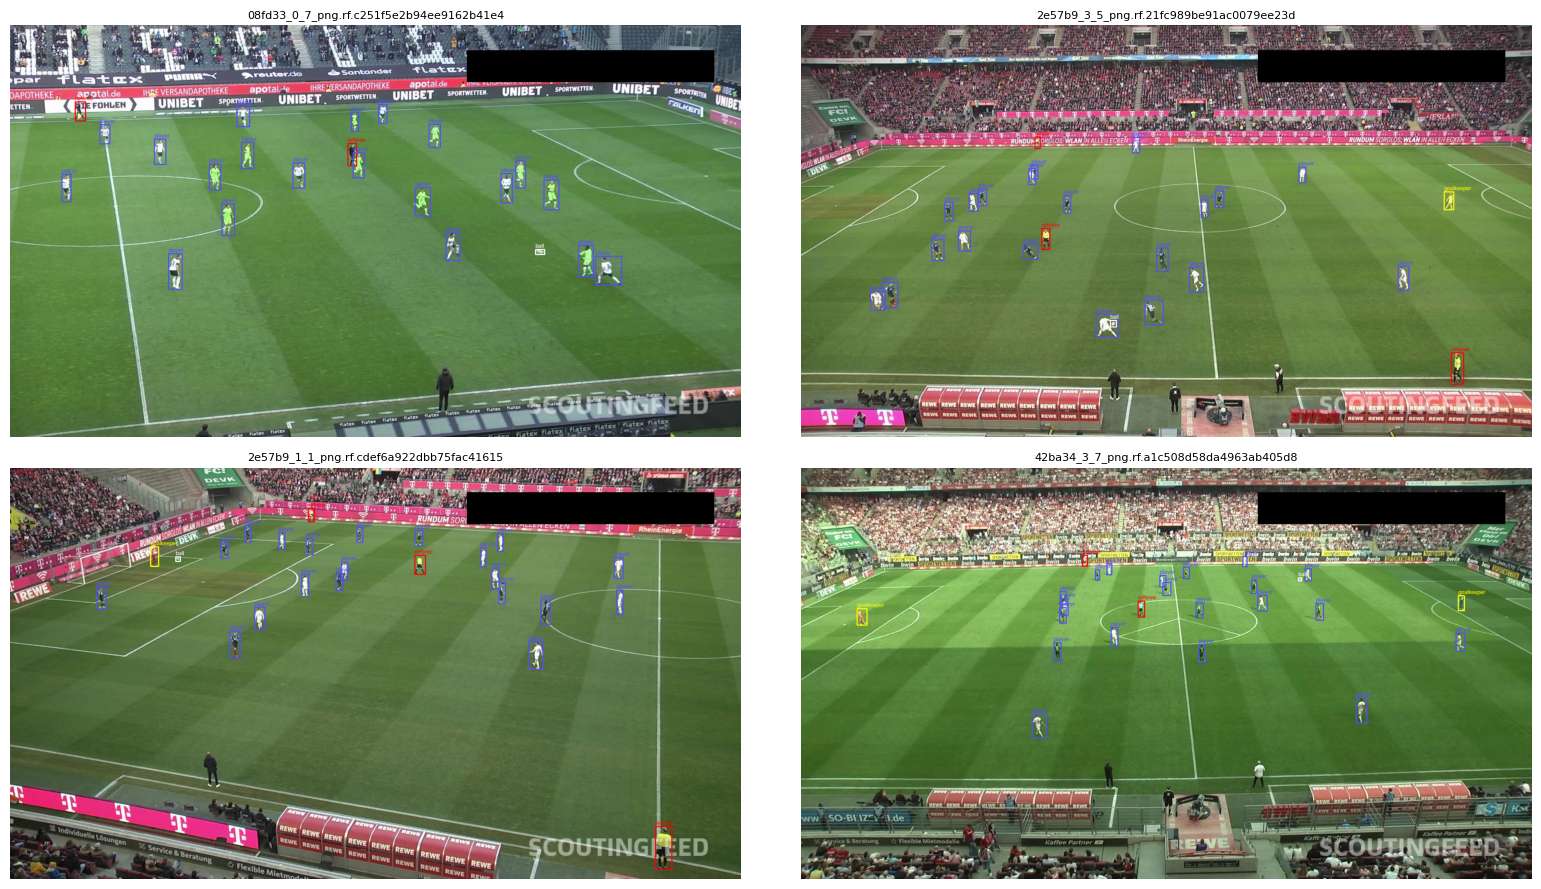

In [11]:
import cv2, numpy as np, random
import matplotlib.pyplot as plt

CORES = {0: (255, 255, 255), 1: (0, 255, 255), 2: (255, 80, 80), 3: (0, 0, 255)}  # BGR

imgs = random.sample(list((DS / "train" / "images").glob("*.jpg")), 4)
fig, axs = plt.subplots(2, 2, figsize=(16, 9))

for ax, img_path in zip(axs.flat, imgs):
    img = cv2.imdecode(np.fromfile(str(img_path), dtype=np.uint8), cv2.IMREAD_COLOR)
    h, w = img.shape[:2]
    lbl = DS / "train" / "labels" / (img_path.stem + ".txt")
    for linha in lbl.read_text().splitlines():
        if not linha.strip():
            continue
        c, xc, yc, bw, bh = map(float, linha.split()[:5])
        x1, y1 = int((xc - bw/2) * w), int((yc - bh/2) * h)
        x2, y2 = int((xc + bw/2) * w), int((yc + bh/2) * h)
        cv2.rectangle(img, (x1, y1), (x2, y2), CORES[int(c)], 2)
        cv2.putText(img, NOMES[int(c)], (x1, y1 - 4), cv2.FONT_HERSHEY_SIMPLEX, 0.5, CORES[int(c)], 1)
    ax.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    ax.set_title(img_path.name[:40], fontsize=8)
    ax.axis("off")

plt.tight_layout(); plt.show()

### Observações sobre as anotações
- As 4 classes estão corretamente anotadas: jogadores (azul), guarda-redes (amarelo), árbitros (vermelho) e bola (branco).
- Os **árbitros assistentes** na linha lateral também estão anotados como `referee`, o que é útil para a deteção de foras de jogo (sinalização com bandeira).
- O dataset **não distingue as equipas**: todos os jogadores de campo são `player`. A atribuição de equipa terá de ser feita numa etapa posterior (por exemplo, por cor do equipamento).
- A bola é um objeto muito pequeno (poucos píxeis), o que justifica treinar com resolução alta (`imgsz=1280`).
- **Diferença de domínio:** as imagens são da Bundesliga, captadas por uma câmara tática larga, enquanto os vídeos da FootAR são transmissões televisivas da Liga Portugal (planos mais próximos, grafismos, mudanças de câmara). Espera-se por isso uma perda de desempenho nos vídeos da FootAR, a confirmar após o treino e a mitigar com o dataset `football-players-and-ball` da FootAR.